In [6]:
# ============================================================
# SECTION D — STEP 1
# DATABASE SETUP
# ============================================================

import sqlite3
import pandas as pd

# Database file name
db_name = "section_d_food_delivery.db"

# Connect to SQLite database
conn = sqlite3.connect(db_name)

# Sample food delivery order data
data = {
    "order_id": range(1, 31),

    "restaurant_name": [
        "Spice Hub", "Spice Hub", "Spice Hub", "Spice Hub", "Spice Hub",
        "Pizza House", "Pizza House", "Pizza House", "Pizza House", "Pizza House",
        "China Bowl", "China Bowl", "China Bowl", "China Bowl", "China Bowl",
        "Food Corner", "Food Corner", "Food Corner", "Food Corner", "Food Corner",
        "Royal Dine", "Royal Dine", "Royal Dine", "Royal Dine", "Royal Dine",
        "Burger Point", "Burger Point", "Burger Point", "Burger Point", "Burger Point"
    ],

    "category": [
        "Indian", "Indian", "Indian", "Indian", "Indian",
        "Italian", "Italian", "Italian", "Italian", "Italian",
        "Chinese", "Chinese", "Chinese", "Chinese", "Chinese",
        "Fast Food", "Fast Food", "Fast Food", "Fast Food", "Fast Food",
        "Indian", "Indian", "Indian", "Indian", "Indian",
        "Fast Food", "Fast Food", "Fast Food", "Fast Food", "Fast Food"
    ],

    "order_value": [
        450, 500, 550, 600, 520,
        700, 750, 650, 800, 720,
        400, 450, 500, 480, 550,
        300, 350, 400, 320, 380,
        900, 850, 950, 1000, 920,
        250, 300, 280, 350, 320
    ],

    "rating": [
        4.8, 4.7, 4.9, 4.8, 4.6,
        4.5, 4.4, 4.6, 4.3, 4.5,
        4.2, 4.1, 4.3, 4.0, 4.2,
        3.8, 3.9, 3.7, 3.8, 3.9,
        4.6, 4.7, 4.5, 4.6, 4.8,
        3.5, 3.6, 3.7, 3.4, 3.6
    ],

    "delivery_time_mins": [
        30, 32, 28, 31, 29,
        35, 37, 34, 36, 33,
        40, 42, 38, 41, 39,
        25, 27, 26, 28, 24,
        45, 43, 46, 44, 42,
        22, 24, 23, 25, 21
    ]
}

# Convert data into DataFrame
orders_df = pd.DataFrame(data)

# Create the required orders table
orders_df.to_sql(
    "orders",
    conn,
    if_exists="replace",
    index=False
)

# Check that table was created
print("✅ Database created successfully.")
print("✅ orders table created successfully.")

# Display first 5 rows
print("\nFirst 5 rows of orders table:")
print(
    pd.read_sql_query(
        "SELECT * FROM orders LIMIT 5",
        conn
    )
)

# Close database connection
conn.close()

✅ Database created successfully.
✅ orders table created successfully.

First 5 rows of orders table:
   order_id restaurant_name category  order_value  rating  delivery_time_mins
0         1       Spice Hub   Indian          450     4.8                  30
1         2       Spice Hub   Indian          500     4.7                  32
2         3       Spice Hub   Indian          550     4.9                  28
3         4       Spice Hub   Indian          600     4.8                  31
4         5       Spice Hub   Indian          520     4.6                  29


Write a Python program that connects to a SQLite database containing a food delivery orders table with the columns:
order_id, restaurant_name, category, order_value, rating, delivery_time_mins.

The program should:
1. Find the top 3 restaurants by average customer rating.
2. Only include restaurants with at least 5 orders.
3. Load the SQL result into a Pandas DataFrame.
4. Add a new column showing each restaurant's revenue share as a percentage of the total revenue across the top 3 restaurants.
5. Plot a horizontal bar chart of the top 3 restaurants by average rating.
6. Display the revenue share percentage as a label on each bar.
7. Handle the case where the database file does not exist.
8. Handle the case where the SQL query returns no rows.
9. Print clear and user-friendly messages.


TOP 3 RESTAURANTS BY AVERAGE RATING
restaurant_name  average_rating  total_revenue  total_orders  revenue_share_percent
      Spice Hub            4.76           2620             5              24.125230
     Royal Dine            4.64           4620             5              42.541436
    Pizza House            4.46           3620             5              33.333333


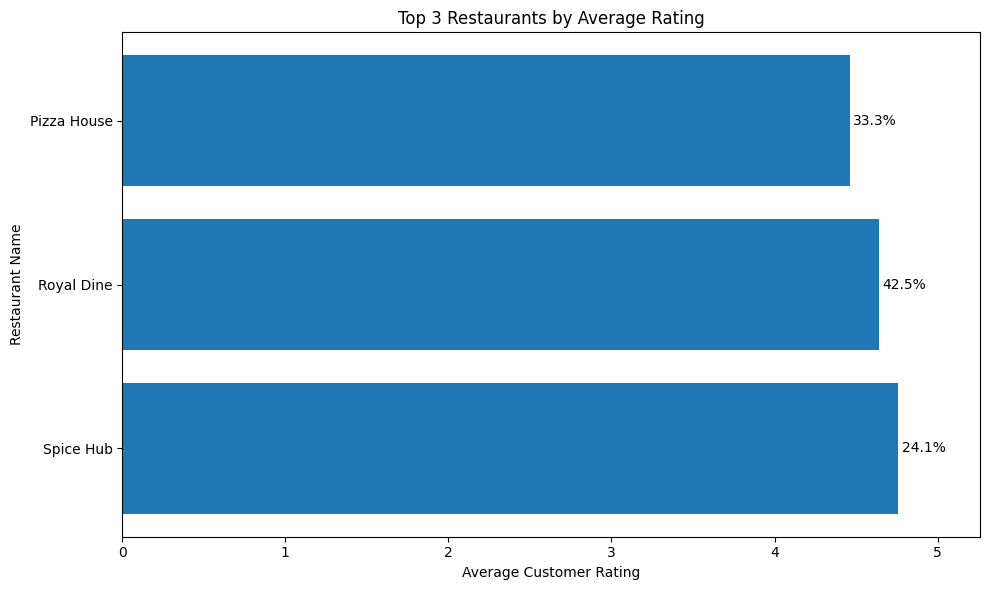


✅ Database connection closed.


In [7]:
# ============================================================
# SECTION D — STEP 2
# CORRECTED VERSION
# ============================================================

import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Database file
# ------------------------------------------------------------

db_name = "section_d_food_delivery.db"


# ------------------------------------------------------------
# 2. Check whether database file exists
# ------------------------------------------------------------

if not os.path.exists(db_name):

    print("❌ Database file does not exist.")
    print("Please create the database before running the analysis.")

else:

    conn = None

    try:

        # ----------------------------------------------------
        # 3. Connect to SQLite database
        # ----------------------------------------------------

        conn = sqlite3.connect(db_name)

        # ----------------------------------------------------
        # 4. Check whether orders table exists
        # ----------------------------------------------------

        table_check = pd.read_sql_query(
            """
            SELECT name
            FROM sqlite_master
            WHERE type = 'table'
            AND name = 'orders'
            """,
            conn
        )

        if table_check.empty:

            print("❌ The 'orders' table does not exist.")
            print("Please create the required orders table first.")

        else:

            # ------------------------------------------------
            # 5. SQL query
            # ------------------------------------------------

            query = """
            SELECT
                restaurant_name,
                AVG(rating) AS average_rating,
                SUM(order_value) AS total_revenue,
                COUNT(order_id) AS total_orders

            FROM orders

            GROUP BY restaurant_name

            HAVING COUNT(order_id) >= 5

            ORDER BY average_rating DESC

            LIMIT 3
            """

            # ------------------------------------------------
            # 6. Load SQL result into Pandas DataFrame
            # ------------------------------------------------

            result = pd.read_sql_query(query, conn)

            # ------------------------------------------------
            # 7. Check whether query returned any rows
            # ------------------------------------------------

            if result.empty:

                print("❌ No restaurants found with at least 5 orders.")

            else:

                # --------------------------------------------
                # 8. Calculate total revenue
                # --------------------------------------------

                total_revenue = result["total_revenue"].sum()

                # --------------------------------------------
                # 9. Prevent division by zero
                # --------------------------------------------

                if total_revenue == 0:

                    print(
                        "❌ Revenue share cannot be calculated "
                        "because total revenue is zero."
                    )

                else:

                    # ----------------------------------------
                    # 10. Calculate revenue share percentage
                    # ----------------------------------------

                    result["revenue_share_percent"] = (
                        result["total_revenue"]
                        / total_revenue
                    ) * 100

                    # ----------------------------------------
                    # 11. Display result
                    # ----------------------------------------

                    print("\n" + "=" * 70)
                    print("TOP 3 RESTAURANTS BY AVERAGE RATING")
                    print("=" * 70)

                    print(
                        result.to_string(index=False)
                    )

                    # ----------------------------------------
                    # 12. Create horizontal bar chart
                    # ----------------------------------------

                    plt.figure(figsize=(10, 6))

                    bars = plt.barh(
                        result["restaurant_name"],
                        result["average_rating"]
                    )

                    # ----------------------------------------
                    # 13. Add revenue share labels
                    # ----------------------------------------

                    for bar, share in zip(
                        bars,
                        result["revenue_share_percent"]
                    ):

                        plt.text(
                            bar.get_width() + 0.02,
                            bar.get_y()
                            + bar.get_height() / 2,
                            f"{share:.1f}%",
                            va="center"
                        )

                    # ----------------------------------------
                    # 14. Chart labels
                    # ----------------------------------------

                    plt.xlabel("Average Customer Rating")
                    plt.ylabel("Restaurant Name")

                    plt.title(
                        "Top 3 Restaurants by Average Rating"
                    )

                    plt.xlim(
                        0,
                        max(result["average_rating"]) + 0.5
                    )

                    plt.tight_layout()
                    plt.show()


    # --------------------------------------------------------
    # 15. Handle SQLite errors
    # --------------------------------------------------------

    except sqlite3.Error as e:

        print("❌ SQLite database error:")
        print(e)


    # --------------------------------------------------------
    # 16. Handle other errors
    # --------------------------------------------------------

    except Exception as e:

        print("❌ Unexpected error:")
        print(e)


    # --------------------------------------------------------
    # 17. Always close database connection
    # --------------------------------------------------------

    finally:

        if conn is not None:

            conn.close()

            print("\n✅ Database connection closed.")

The AI-generated code assumed that an orders table already existed in the SQLite database.
When I tested it, the program produced a "no such table: orders" error.
I fixed this by creating the required orders table and adding a check to verify that the table exists.
I also added checks for an empty result and zero total revenue, and safely closed the database connection.